<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Final loss: 0.0885961528669828


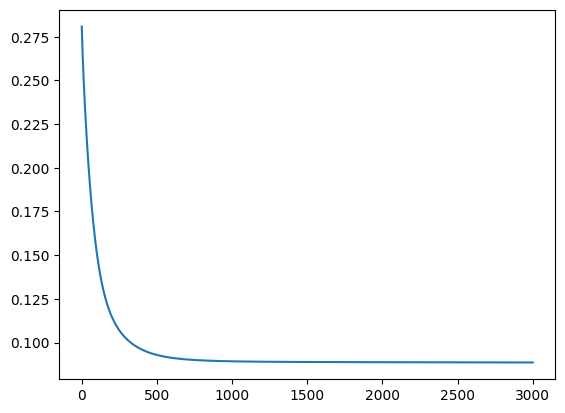

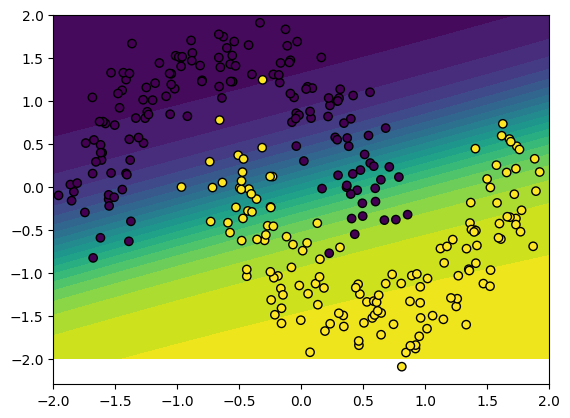

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_moons
X,y=make_moons(300,noise=.15,random_state=1); X=(X-X.mean(0))/X.std(0)
rng=np.random.default_rng(8); W1=rng.normal(size=(2,8))*.5; W2=rng.normal(size=(8,1))*.5; b1=np.zeros(8); b2=np.zeros(1)
sig=lambda z:1/(1+np.exp(-np.clip(z,-30,30)))
losses=[]
for epoch in range(3000):
 h=sig(X@W1+b1); o=sig(h@W2+b2); loss=np.mean((o[:,0]-y)**2); losses.append(loss)
 d=(o-y[:,None])*o*(1-o)/len(y); dW2=h.T@d; db2=d.sum(0); dh=d@W2.T*h*(1-h); dW1=X.T@dh; db1=dh.sum(0)
 W1-=.5*dW1; W2-=.5*dW2; b1-=.5*db1; b2-=.5*db2
print('Final loss:',losses[-1])
plt.plot(losses); plt.show()
xx,yy=np.meshgrid(np.linspace(-2,2,100),np.linspace(-2,2,100)); grid=np.c_[xx.ravel(),yy.ravel()]; pred=sig(sig(grid@W1+b1)@W2+b2).reshape(xx.shape)
plt.contourf(xx,yy,pred,levels=20); plt.scatter(X[:,0],X[:,1],c=y,edgecolors='k'); plt.show()